# Признаки из логов прослушивания и SHAP

Вопрос: улучшают ли признаки из логов прослушивания модель оттока, и как модель использует признаки (SHAP).

Логи сохранены для выборки клиентов (10% по хешу `msno`), поэтому сравнение возможно только на ней: около 99 тысяч клиентов февраля 2017 и 97 тысяч клиентов марта 2017.
Признаки из логов (`scripts/06_log_features.py`): три окна по 30 дней перед датой прогноза (дни прослушивания, число прослушиваний, время, уникальные песни,
доля дослушанных и пропущенных песен, динамика активности, дней с последнего прослушивания). Логи месяца окончания подписки не используются.

**Схема сравнения.** Модель A (LightGBM на 32 прежних признаках) и модель B (те же признаки плюс признаки из логов) обучаются на одной и той же подвыборке клиентов февраля
с одинаковой процедурой: 80% для обучения, 20% для подбора параметров из небольшой сетки и ранней остановки, затем оценка на марте. Модель из `07_churn_model.ipynb`
(обучена на всех 800 тысячах клиентов) приводится для справки, а не как точка сравнения: она учится на другом объёме данных.
Разность метрик B − A сопровождается доверительным интервалом 95%: пары предсказаний для клиентов марта перевыбираются с возвращением (парный бутстрэп, 500 повторов).
Интерпретация: распределение разности показывает, отличается ли прирост от шума выборки.

In [1]:
import json

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split

P = "/workspace/data/processed/"
TRAIN_MONTH, TEST_MONTH = "2017-02-01", "2017-03-01"
RARE_MIN = 1000 * 0.1  # порог редкой категории в подвыборке (10% клиентов)
SEED = 42
N_BOOT = 500
N_SHAP = 20000
INK, BLUE, ORANGE, GREEN, GRAY = "#2b2f36", "#0072B2", "#E69F00", "#009E73", "#8a8f98"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

BASE_NUM = [
    "last_plan_days", "last_list_price", "last_paid", "last_auto_renew", "last_is_cancel", "last_discount",
    "days_to_expire", "days_since_last_tx", "tenure_days", "n_tx", "n_cancel", "share_cancel", "n_paid_tx",
    "total_paid", "avg_paid", "share_zero_paid", "share_discount", "share_auto_renew", "n_plans", "n_methods",
    "n_tx_30d", "n_tx_90d", "n_plan_changes", "n_method_changes", "n_lapses", "has_profile", "age", "reg_tenure_days",
]
CAT = ["last_method", "city", "gender", "registered_via"]
LOG_NUM = [f"{w}_{m}" for w in ("l30", "l60", "l90") for m in ("days", "plays", "secs", "unq", "full_share", "skip_share")] + [
    "l30_secs_per_day", "secs_ratio_30_60", "days_ratio_30_60", "days_since_last_listen",
]

con = duckdb.connect()
df = con.sql(f'''
    SELECT
        f.*,
        g.* EXCLUDE (msno, expire_month)
    FROM '{P}churn_features.parquet' f
    JOIN '{P}log_features.parquet' g USING (msno, expire_month)
''').df()
df["expire_month"] = df["expire_month"].dt.strftime("%Y-%m-%d")
print(df.groupby("expire_month").agg(клиентов=("msno", "size"), доля_оттока=("is_churn", "mean")).round(4))
print("клиентов без прослушиваний за 90 дней, %:", round(100 * (df.l30_days + df.l60_days + df.l90_days == 0).mean(), 1))

              клиентов  доля_оттока
expire_month                       
2017-02-01       99406       0.0651
2017-03-01       97079       0.0918
клиентов без прослушиваний за 90 дней, %: 18.5


## 1. Разбиение и подготовка признаков
Как в `07_churn_model.ipynb`: февраль делится на `fit` (80%) и `valid` (20%), март это `test`. Преобразования (обрезка по квантилям 0,1% и 99,9%, объединение редких категорий в «other»)
обучаются на `fit`. Порог редкой категории уменьшен пропорционально размеру подвыборки.

In [2]:
y = df["is_churn"].to_numpy()
is_train = (df["expire_month"] == TRAIN_MONTH).to_numpy()
idx_train = np.flatnonzero(is_train)
idx_fit, idx_valid = train_test_split(idx_train, test_size=0.2, stratify=y[idx_train], random_state=SEED)
idx_test = np.flatnonzero(~is_train)
print({"fit": len(idx_fit), "valid": len(idx_valid), "test": len(idx_test)})

NUM_ALL = BASE_NUM + LOG_NUM
lo = df.loc[idx_fit, NUM_ALL].astype(float).quantile(0.001)
hi = df.loc[idx_fit, NUM_ALL].astype(float).quantile(0.999)
frequent = {}
for c in CAT:
    counts = df.loc[idx_fit, c].astype("string").fillna("missing").value_counts()
    frequent[c] = set(counts[counts >= RARE_MIN].index) | {"missing"}

X = df[NUM_ALL].astype(float).clip(lower=lo, upper=hi, axis=1)
for c in CAT:
    s = df[c].astype("string").fillna("missing")
    X[c] = pd.Categorical(s.where(s.isin(frequent[c]), "other"), categories=sorted(frequent[c] | {"other"}))

FEATS_A = BASE_NUM + CAT
FEATS_B = BASE_NUM + LOG_NUM + CAT
print("признаков в модели A:", len(FEATS_A), " в модели B:", len(FEATS_B))

{'fit': 79524, 'valid': 19882, 'test': 97079}


признаков в модели A: 32  в модели B: 54


## 2. Метрики и журнал MLflow
Те же функции, что в `07_churn_model.ipynb`.

In [3]:
mlflow.set_tracking_uri("http://mlflow:5000")
EXPERIMENT = "churn_model"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location="mlflow-artifacts:/churn_model")
mlflow.set_experiment(EXPERIMENT)


def evaluate(y_true: np.ndarray, p: np.ndarray) -> dict:
    '''Считает метрики качества вероятностей оттока.

    Args:
        y_true (np.ndarray): фактические метки (1: отток).
        p (np.ndarray): предсказанные вероятности оттока.

    Returns:
        dict: logloss, pr_auc, roc_auc, среднее предсказание и фактическая доля оттока.
    '''
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {
        "logloss": log_loss(y_true, p),
        "pr_auc": average_precision_score(y_true, p),
        "roc_auc": roc_auc_score(y_true, p),
        "mean_pred": float(p.mean()),
        "actual_rate": float(y_true.mean()),
    }

## 3. Обучение моделей A и B
Для каждой модели две конфигурации деревьев (меньше и больше листьев), число деревьев определяется ранней остановкой по logloss на `valid`;
из двух конфигураций выбирается лучшая по `valid`. Март в подборе не участвует.

In [4]:
BASE_PARAMS = {
    "n_estimators": 2000, "learning_rate": 0.05, "subsample": 0.8, "subsample_freq": 1,
    "colsample_bytree": 0.8, "reg_lambda": 1.0, "random_state": SEED, "n_jobs": 2, "verbose": -1,
}
GRID = [{"num_leaves": 15, "min_child_samples": 50}, {"num_leaves": 31, "min_child_samples": 100}]


def fit_lgbm(feats: list) -> tuple:
    '''Обучает LightGBM на `fit` с подбором конфигурации по `valid`.

    Args:
        feats (list): список признаков.

    Returns:
        tuple: лучшая модель, её параметры, предсказания для всех строк таблицы.
    '''
    best = None
    for params in GRID:
        clf = lgb.LGBMClassifier(**BASE_PARAMS, **params)
        clf.fit(
            X.iloc[idx_fit][feats], y[idx_fit],
            eval_set=[(X.iloc[idx_valid][feats], y[idx_valid])], eval_metric="binary_logloss",
            callbacks=[lgb.early_stopping(50, verbose=False)],
        )
        loss = log_loss(y[idx_valid], clf.predict_proba(X.iloc[idx_valid][feats])[:, 1])
        print(params, "деревьев:", clf.best_iteration_, "valid logloss:", round(loss, 5))
        if best is None or loss < best[0]:
            best = (loss, params, clf)
    _, params, clf = best
    return clf, params, clf.predict_proba(X[feats])[:, 1]


print("Модель A (без логов)")
clf_a, params_a, p_a = fit_lgbm(FEATS_A)
print("Модель B (с логами)")
clf_b, params_b, p_b = fit_lgbm(FEATS_B)

Модель A (без логов)


{'num_leaves': 15, 'min_child_samples': 50} деревьев: 202 valid logloss: 0.1495


{'num_leaves': 31, 'min_child_samples': 100} деревьев: 129 valid logloss: 0.14964


Модель B (с логами)


{'num_leaves': 15, 'min_child_samples': 50} деревьев: 196 valid logloss: 0.14577


{'num_leaves': 31, 'min_child_samples': 100} деревьев: 112 valid logloss: 0.14556


## 4. Сравнение A и B на марте
Метрики на тесте. Для справки добавлена модель из `07_churn_model.ipynb` (предсказания по тем же клиентам марта, обучение на всех клиентах февраля).
Разность B − A: для logloss отрицательное значение означает улучшение, для PR-AUC и ROC-AUC положительное. Интервалы получены парным бутстрэпом по клиентам марта.

In [5]:
y_test = y[idx_test]
res = {
    "A: без логов": evaluate(y_test, p_a[idx_test]),
    "B: с логами": evaluate(y_test, p_b[idx_test]),
}
full = con.sql(f'''
    SELECT
        msno,
        p_lgbm
    FROM '{P}churn_predictions.parquet'
''').df().set_index("msno").p_lgbm
p_full = df.iloc[idx_test].msno.map(full).to_numpy()
res["справка: модель из 07 (все клиенты)"] = evaluate(y_test, p_full)
pd.DataFrame(res).T.round(4)

,logloss,pr_auc,roc_auc,mean_pred,actual_rate
A: без логов,0.2084,0.5877,0.8661,0.0655,0.0918
B: с логами,0.2070,0.5961,0.8649,0.0666,0.0918
справка: модель из 07 (все клиенты),0.2100,0.5918,0.8587,0.0640,0.0918


In [6]:
def paired_bootstrap(y_true: np.ndarray, p_a: np.ndarray, p_b: np.ndarray, n_boot: int = N_BOOT, seed: int = SEED) -> dict:
    '''Оценивает разность метрик моделей B и A парным бутстрэпом по клиентам.

    Args:
        y_true (np.ndarray): фактические метки.
        p_a (np.ndarray): предсказания модели A.
        p_b (np.ndarray): предсказания модели B.
        n_boot (int): число повторов.
        seed (int): начальное значение генератора случайных чисел.

    Returns:
        dict: для каждой метрики среднее, нижняя и верхняя границы 95% интервала разности B - A.
    '''
    rng = np.random.default_rng(seed)
    n = len(y_true)
    pa, pb = np.clip(p_a, 1e-6, 1 - 1e-6), np.clip(p_b, 1e-6, 1 - 1e-6)
    d = {"logloss": [], "pr_auc": [], "roc_auc": []}
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        yy = y_true[i]
        d["logloss"].append(log_loss(yy, pb[i]) - log_loss(yy, pa[i]))
        d["pr_auc"].append(average_precision_score(yy, pb[i]) - average_precision_score(yy, pa[i]))
        d["roc_auc"].append(roc_auc_score(yy, pb[i]) - roc_auc_score(yy, pa[i]))
    return {k: (float(np.mean(v)), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in d.items()}


delta = paired_bootstrap(y_test, p_a[idx_test], p_b[idx_test])
pd.DataFrame(delta, index=["разность B - A", "нижняя 95%", "верхняя 95%"]).T.round(4)

,разность B - A,нижняя 95%,верхняя 95%
logloss,-0.0015,-0.0022,-0.0007
pr_auc,0.0084,0.0045,0.0120
roc_auc,-0.0011,-0.0027,0.0006


## 5. Прирост по группам
Те же метрики по клиентам с автопродлением и без него. Ожидание: у клиентов без автопродления решение о продлении принимается активно, и поведение в сервисе может быть информативнее.

In [7]:
test_df = df.iloc[idx_test].assign(p_a=p_a[idx_test], p_b=p_b[idx_test])
rows = {}
for name, mask in [("автопродление", test_df.last_auto_renew == 1), ("без автопродления", test_df.last_auto_renew == 0)]:
    g = test_df[mask]
    ma, mb = evaluate(g.is_churn.to_numpy(), g.p_a.to_numpy()), evaluate(g.is_churn.to_numpy(), g.p_b.to_numpy())
    rows[name] = {
        "клиентов": len(g), "доля оттока": g.is_churn.mean(),
        "logloss A": ma["logloss"], "logloss B": mb["logloss"],
        "PR-AUC A": ma["pr_auc"], "PR-AUC B": mb["pr_auc"],
        "ROC-AUC A": ma["roc_auc"], "ROC-AUC B": mb["roc_auc"],
    }
pd.DataFrame(rows).T.round(4)

,клиентов,доля оттока,logloss A,logloss B,PR-AUC A,PR-AUC B,ROC-AUC A,ROC-AUC B
автопродление,85539.0,0.0467,0.1569,0.1560,0.3381,0.3447,0.7662,0.7625
без автопродления,11320.0,0.4241,0.5862,0.5806,0.7354,0.7391,0.7719,0.7761


## 6. Важность признаков модели B (gain)
Суммарный прирост качества от разбиений по признаку. Отдельно показана суммарная доля признаков из логов.

доля gain признаков из логов: 15.2 %


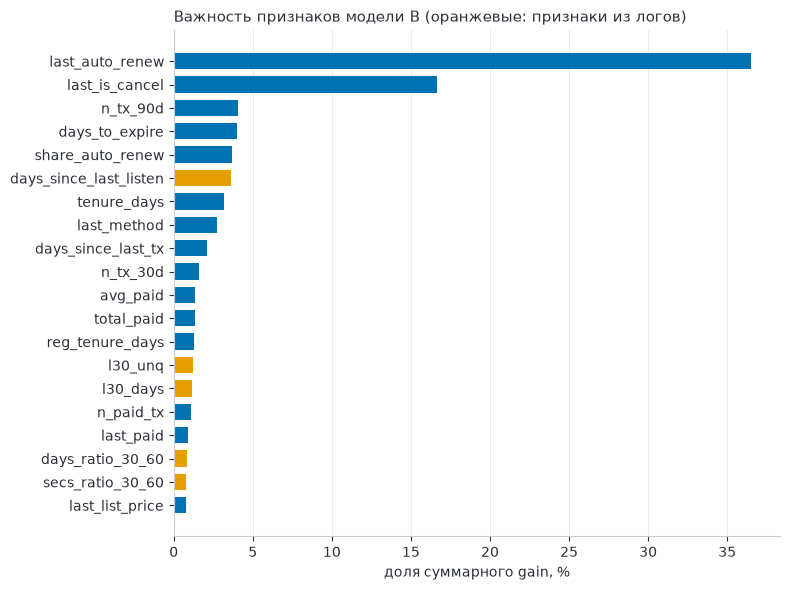

,"доля gain, %"
last_auto_renew,36.51
last_is_cancel,16.67
n_tx_90d,4.05
days_to_expire,3.97
share_auto_renew,3.67
days_since_last_listen,3.63
tenure_days,3.17
last_method,2.72
days_since_last_tx,2.09
n_tx_30d,1.63


In [8]:
imp = pd.Series(clf_b.booster_.feature_importance(importance_type="gain"), index=clf_b.booster_.feature_name()).sort_values(ascending=False)
imp_share = 100 * imp / imp.sum()
print("доля gain признаков из логов:", round(imp_share[imp_share.index.isin(LOG_NUM)].sum(), 1), "%")
top = imp_share.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=[ORANGE if f in LOG_NUM else BLUE for f in top.index], height=0.7)
ax.set_xlabel("доля суммарного gain, %")
ax.set_title("Важность признаков модели B (оранжевые: признаки из логов)", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout()
fig_imp = fig
plt.show()
imp_share.head(15).round(2).to_frame("доля gain, %")

## 7. SHAP
Значения SHAP показывают вклад каждого признака в предсказание для конкретного клиента (в логарифме шансов): положительное значение увеличивает вероятность оттока, отрицательное уменьшает.
Расчёт на случайных клиентах теста (`N_SHAP`). Сводный график: каждая точка это клиент; положение по горизонтали это вклад признака, цвет это значение признака (красный: большое).
Среднее абсолютное значение SHAP измеряет важность признака и в отличие от gain учитывает вклад в конкретные предсказания. Как и любая интерпретация, SHAP описывает модель, а не причинные связи.

/usr/local/lib/python3.12/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


форма значений SHAP: (20000, 54)


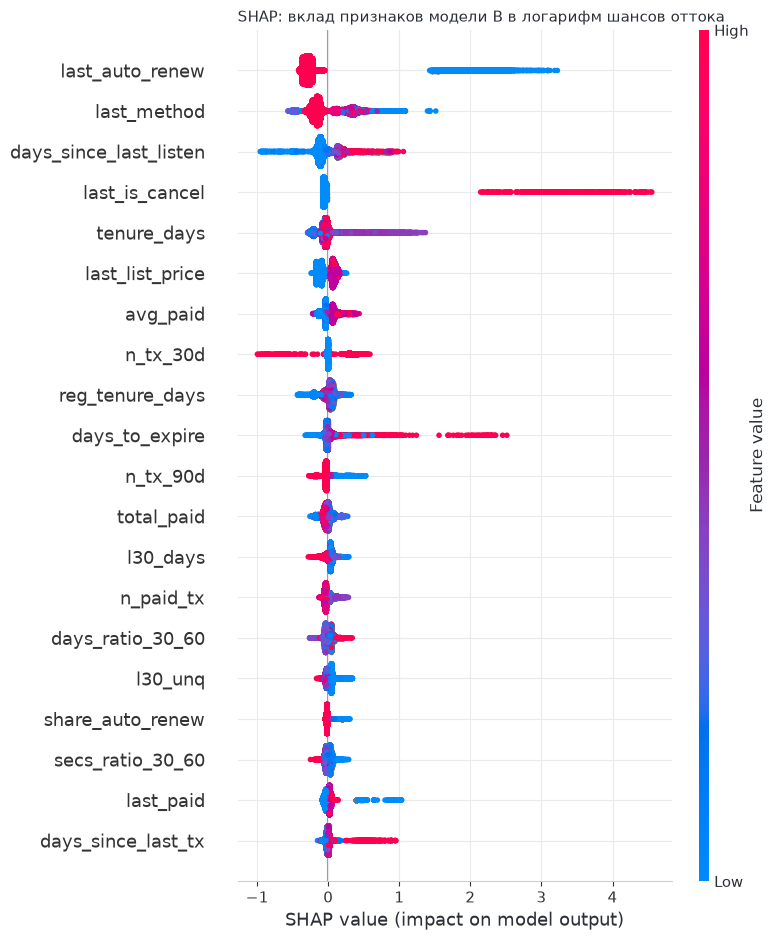

In [9]:
rng = np.random.default_rng(SEED)
pos = rng.choice(len(idx_test), min(N_SHAP, len(idx_test)), replace=False)
Xs = X.iloc[idx_test[pos]][FEATS_B]
explainer = shap.TreeExplainer(clf_b)
sv = explainer.shap_values(Xs)
if isinstance(sv, list):
    sv = sv[1]
sv = np.asarray(sv)
if sv.ndim == 3:
    sv = sv[:, :, 1]
Xs_plot = Xs.copy()
for c in CAT:
    Xs_plot[c] = Xs_plot[c].cat.codes
print("форма значений SHAP:", sv.shape)

plt.figure(figsize=(9, 8))
shap.summary_plot(sv, Xs_plot, max_display=20, show=False)
plt.title("SHAP: вклад признаков модели B в логарифм шансов оттока", loc="left", fontsize=11)
plt.tight_layout()
fig_shap = plt.gcf()
plt.show()

In [10]:
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=FEATS_B).sort_values(ascending=False)
cmp = pd.DataFrame({
    "среднее |SHAP|": mean_abs.head(15),
    "место по SHAP": range(1, 16),
})
cmp["место по gain"] = [int(imp.index.get_loc(f)) + 1 for f in cmp.index]
cmp["из логов"] = [f in LOG_NUM for f in cmp.index]
cmp.round(4)

,среднее |SHAP|,место по SHAP,место по gain,из логов
last_auto_renew,0.4900,1,1,False
last_method,0.2353,2,8,False
days_since_last_listen,0.1317,3,6,True
last_is_cancel,0.1078,4,2,False
tenure_days,0.1063,5,7,False
last_list_price,0.0890,6,20,False
avg_paid,0.0809,7,11,False
n_tx_30d,0.0746,8,10,False
reg_tenure_days,0.0639,9,13,False
days_to_expire,0.0539,10,4,False


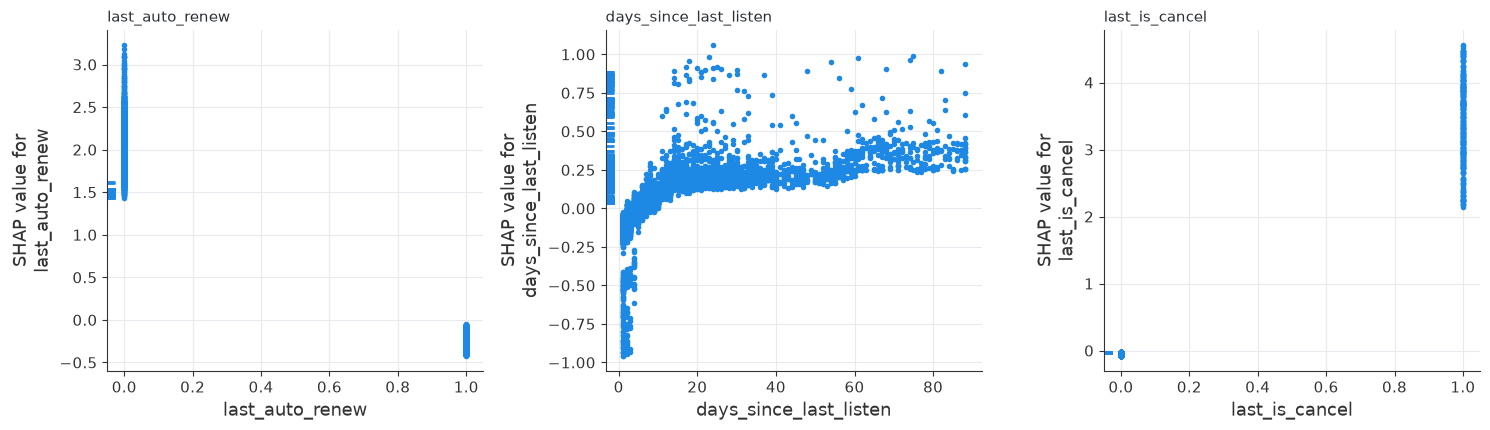

,среднее SHAP при автопродлении,среднее SHAP без автопродления
0,-0.291,1.998


In [11]:
num_top = [f for f in mean_abs.index if f not in CAT][:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, f in zip(axes, num_top):
    shap.dependence_plot(f, sv, Xs_plot, interaction_index=None, ax=ax, show=False)
    ax.set_title(f, loc="left", fontsize=11)
plt.tight_layout()
fig_dep = fig
plt.show()
pd.DataFrame({
    "среднее SHAP при автопродлении": [sv[Xs.last_auto_renew.to_numpy() == 1, FEATS_B.index("last_auto_renew")].mean()],
    "среднее SHAP без автопродления": [sv[Xs.last_auto_renew.to_numpy() == 0, FEATS_B.index("last_auto_renew")].mean()],
}).round(3)

## 8. Запись в MLflow
Запуски `logs_A_base_subset` и `logs_B_with_logs`: параметры, метрики на `valid` и `test`, для B также модель, графики и разности метрик B − A с границами интервала.

In [12]:
def valid_test_metrics(p: np.ndarray) -> dict:
    '''Считает метрики на valid и test с префиксами.

    Args:
        p (np.ndarray): предсказания для всех строк таблицы.

    Returns:
        dict: метрики с префиксами valid_ и test_.
    '''
    out = {}
    for split, idx in [("valid", idx_valid), ("test", idx_test)]:
        out.update({f"{split}_{k}": v for k, v in evaluate(y[idx], p[idx]).items()})
    return out


with mlflow.start_run(run_name="logs_A_base_subset"):
    mlflow.log_params({**params_a, "best_iteration": clf_a.best_iteration_, "n_features": len(FEATS_A), "subset": "clients_with_logs"})
    mlflow.log_metrics(valid_test_metrics(p_a))
    mlflow.set_tag("stage", "logs_ablation")

with mlflow.start_run(run_name="logs_B_with_logs"):
    mlflow.log_params({**params_b, "best_iteration": clf_b.best_iteration_, "n_features": len(FEATS_B), "subset": "clients_with_logs"})
    mlflow.log_metrics(valid_test_metrics(p_b))
    for k, (m, lo_, hi_) in delta.items():
        mlflow.log_metrics({f"delta_{k}": m, f"delta_{k}_lo95": lo_, f"delta_{k}_hi95": hi_})
    mlflow.set_tag("stage", "logs_ablation")
    mlflow.log_dict({"base": BASE_NUM, "logs": LOG_NUM, "cat": CAT}, "features.json")
    mlflow.lightgbm.log_model(clf_b, name="model")
    mlflow.log_figure(fig_imp, "feature_importance.png")
    mlflow.log_figure(fig_shap, "shap_summary.png")
    mlflow.log_figure(fig_dep, "shap_dependence.png")
print("записано в MLflow, интерфейс: http://localhost:5001")

2026/10/27 14:13:56 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/27 14:13:56 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git branch is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/27 14:13:56 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git repository URL is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



🏃 View run logs_A_base_subset at: http://mlflow:5000/#/experiments/1/runs/7c7dd4520e01432aafd94608e6c0bf04
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run logs_B_with_logs at: http://mlflow:5000/#/experiments/1/runs/981ad9eb356b499e9a8e393c8169eee1
🧪 View experiment at: http://mlflow:5000/#/experiments/1
записано в MLflow, интерфейс: http://localhost:5001


## Выводы
- **Прирост от логов небольшой, но статистически отличим от шума по двум метрикам из трёх.** На клиентах марта с логами (97 079) logloss снижается с 0,2084 до 0,2070 (разность −0,0015, 95% интервал от −0,0022 до −0,0007), PR-AUC растёт с 0,5877 до 0,5961 (+0,0084, интервал от +0,0045 до +0,0120). ROC-AUC не меняется: 0,8661 против 0,8649 (разность −0,0011, интервал от −0,0027 до +0,0006 включает ноль).
- **Калибровка не улучшилась.** Среднее предсказание 6,6% при фактической доле оттока 9,2% (у модели без логов 6,5%): занижение, вызванное сдвигом между февралём и мартом, логи не устраняют.
- **По группам.** У клиентов без автопродления (11 320, отток 42,4%) логи дают logloss 0,5862 → 0,5806, PR-AUC 0,7354 → 0,7391, ROC-AUC 0,7719 → 0,7761. У клиентов с автопродлением (85 539, отток 4,7%) logloss 0,1569 → 0,1560, PR-AUC 0,3381 → 0,3447, ROC-AUC 0,7662 → 0,7625 (небольшое ухудшение). Различия в группах малы и в группах интервалы не оценивались.
- **Роль признаков из логов.** На них приходится 15,2% суммарного gain. Самый заметный признак из логов: число дней с последнего прослушивания (6-е место по gain, 3-е по среднему |SHAP|); затем число дней прослушивания за последние 30 дней и отношение числа дней за 30 и 60 дней. Основу модели по-прежнему составляют признаки транзакций.
- **Объём обучающих данных не ограничивает качество.** Модель A, обученная на 79 тысячах клиентов, на тех же клиентах марта показывает logloss 0,2084, PR-AUC 0,5877, ROC-AUC 0,8661; модель из `07_churn_model.ipynb`, обученная на 800 тысячах клиентов, на них даёт 0,2100, 0,5918 и 0,8587. Большой объём данных не помогает: качество на марте ограничено различием между февралём и мартом.
- **SHAP.** Наибольший средний вклад у автопродления: среднее значение SHAP у клиентов без автопродления +2,00 (рост логарифма шансов оттока), с автопродлением −0,29. Далее по среднему |SHAP|: способ оплаты последней транзакции, число дней с последнего прослушивания, признак отмены в последней транзакции, стаж. Порядок по SHAP и по gain различается (способ оплаты 2-й по SHAP и 8-й по gain; цена по прайсу 6-й по SHAP и 20-й по gain), поэтому важность по одному показателю нельзя считать окончательной. Графики и таблица сравнения в разделе 7.
- **Ограничения.** Логи есть только для выборки 10% клиентов, поэтому сравнение сделано на ней; интервалы учитывают случайность выбора клиентов марта, но не неопределённость обучения (одно разбиение февраля). Прирост логов умеренный: решение, стоит ли строить признаки для всех клиентов (около 410 млн строк логов), зависит от стоимости обработки и требуемой точности.
